In [22]:
import matplotlib.pyplot as plt
import hyperspy.api as hs
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap
from pathlib import Path
import numpy as np
import imageio
from skimage.measure import block_reduce
from PIL import Image
import tifffile
%matplotlib inline

In [24]:
# list of labellings as save in FIJI

#root = r'C:\DataCNRS\DropSU\Shared\LRS-FCMAT_DL_data\AuCu%SiO2'  # LRS desktop
root_Path = Path(r'C:\Users\Axel\Nextcloud2\dataProcessing\DeepLearning\2026-09_SELENA') # Home desktop
AuCuSiO2_Path = root_Path / r'AuCu%SiO2\SS57-SiO2-Cal'
save_Path = AuCuSiO2_Path / r'trainingData'
#image_path = r'SS57-SiO2-Cal\30kX-ss57-Au45Cu55-SiO2-CALC-0001'
#image_path = r'SS57-SiO2-Cal\30kX-ss57-Au45Cu55-SiO2-CALC-0002'
#image_path = r'SS57-SiO2-Cal\60kX-ss57-Au45Cu55-SiO2-CALC-0003'
#image_path = r'SS57-SiO2-Cal\60kX-ss57-Au45Cu55-SiO2-CALC-0004' # problem
#image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0005'
#image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0006'
image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0008'


In [5]:
def checkLabbeling(image):
    label_array = np.array(Image.open(f"{image}_lab_mod.tif"))
    unique_values = np.unique(label_array) # Get unique values

    # Check if there are exactly 3 non-zero values (assuming 0 is unlabelled)
    if len(unique_values) != 3:
        raise ValueError("Unlabelled pixels or incorrect number of labels: expected exactly 3 unique values.")
    else:
        print("no unasigned pixels")
    return "No unasigned pixels"

def bin_grayscale_data(data):
    """Bin grayscale data by 2x2 averaging (halves resolution)."""
    if data.ndim != 2:
        raise ValueError("Input must be a 2D grayscale array.")

    # Reshape into 2x2 blocks and average
    h, w = data.shape
    binned = data[:h//2*2, :w//2*2].reshape(h//2, 2, w//2, 2).mean(axis=(1, 3))
    return binned.astype(data.dtype)

def bin_label_data(label):
    """Bin labeled data by 2x2 mode filtering using NumPy."""
    if label.ndim != 2:
        raise ValueError("Input must be a 2D label array.")

    h, w = label.shape
    # Trim to even dimensions
    h_trim, w_trim = h // 2 * 2, w // 2 * 2
    trimmed_label = label[:h_trim, :w_trim]

    # Reshape into 2x2 blocks
    blocks = trimmed_label.reshape(h_trim // 2, 2, w_trim // 2, 2)

    # Compute mode for each block
    mode_values = np.zeros((h_trim // 2, w_trim // 2), dtype=label.dtype)
    for i in range(h_trim // 2):
        for j in range(w_trim // 2):
            block = blocks[i, :, j, :]
            mode_values[i, j] = np.bincount(block.ravel()).argmax()

    return mode_values

In [18]:
image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0005'
imageToPlot = AuCuSiO2_Path / image_path

label_array = bin_label_data(np.array(Image.open(f"{imageToPlot}_lab_mod.tif")))

print(f"shape : {}, "label_array.shape

(1336, 2004)

In [ ]:
img_array = hs.load(f"{imageToPlot}.dm3").data
print(f"img_array shape : {img_array.shape}, img_array type {img_array.dtype}"
img_array.plot()

In [ ]:
print(f"img_array dtype: {img_array.dtype}")
print(f"label_array dtype: {label_array.dtype}")

In [ ]:
# Remap the values: 1→3, 2→1, 3→2
image_path2 = r'60kX-ss57-Au45Cu55-SiO2-CALC-0008'
imageToPlot2 = AuCuSiO2_Path / image_path2

label_array = np.array(Image.open(f"{imageToPlot2}_lab_mod2.tif"))  # Replace with your label image path


remapped_array = np.copy(label_array)
remapped_array[label_array == 1] = 3  # Green → Red
remapped_array[label_array == 2] = 1  # Blue → Green
remapped_array[label_array == 3] = 2  # Red → Blue

# Plot the remapped array
plt.imshow(remapped_array, cmap=cmap, vmin=1, vmax=3)
remapped_image = Image.fromarray(remapped_array.astype(np.uint8))
remapped_image.save("60kX-ss57-Au45Cu55-SiO2-CALC-0008_lab_mod.tif")

no unasigned pixels
no unasigned pixels


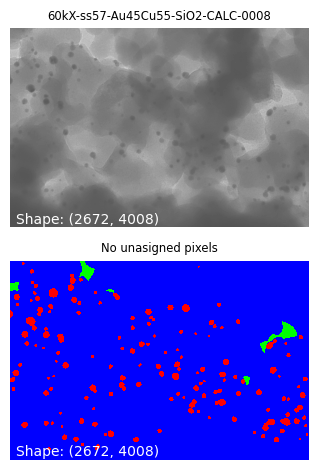

In [8]:
# i use this

#image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0005'
#image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0006'
image_path = r'60kX-ss57-Au45Cu55-SiO2-CALC-0008'

imageToPlot = AuCuSiO2_Path / image_path
checkLabbeling(imageToPlot)

binBy2 = False

if binBy2 == True:
    img_array = bin_grayscale_data(hs.load(f"{imageToPlot}.dm3").data)
    label_array = bin_label_data(np.array(Image.open(f"{imageToPlot}_lab_mod.tif")))
else:
    img_array = hs.load(f"{imageToPlot}.dm3").data
    label_array = np.array(Image.open(f"{imageToPlot}_lab_mod.tif"))

# Define colors for the labeled image
colors = [
    [0, 1, 0, 1],    # Value 1 (green)
    [0, 0, 1, 1],    # Value 2 (blue)
    [1, 0, 0, 1]     # Value 3 (red)
]
cmap = ListedColormap(colors)

# Create a figure with two subplots
fig, axes = plt.subplots(2, 1)

axes[0].imshow(img_array.data, cmap='gray')
axes[0].axis('off')
axes[0].set_title(image_path, fontsize="small")
axes[0].text(0.02, 0.02, f"Shape: {img_array.data.shape}",
             transform=axes[0].transAxes,
             color='white', fontsize=10)

axes[1].imshow(label_array, cmap=cmap, vmin=1, vmax=3)
axes[1].axis('off')
axes[1].set_title(checkLabbeling(imageToPlot), fontsize="small")
axes[1].text(0.02, 0.02, f"Shape: {label_array.shape}",
             transform=axes[1].transAxes,
             color='white', fontsize=10)

plt.tight_layout()
plt.show()

In [10]:


# Check the data type of label_array


img_array dtype: float32
label_array dtype: uint8


In [14]:
img_array

array([[683.1308 , 766.45654, 745.5923 , ..., 720.50446, 722.5559 ,
        756.243  ],
       [696.1071 , 672.31854, 734.5596 , ..., 679.9075 , 718.7513 ,
        724.9804 ],
       [716.0649 , 737.84705, 736.5959 , ..., 678.1826 , 771.28253,
        739.81146],
       ...,
       [110.71492, 118.22319, 144.68683, ..., 865.0716 , 840.4817 ,
        868.1422 ],
       [121.9571 , 120.15926, 144.339  , ..., 866.7199 , 815.8973 ,
        852.4305 ],
       [129.37422, 118.18785, 135.77965, ..., 848.99097, 887.5333 ,
        853.4737 ]], dtype=float32)

In [30]:
test = (img_array - img_array.min()) / (img_array.max() - img_array.min())
test

tifffile.imwrite('test.tif', test)

In [38]:
read_fda(img)

TypeError: unhashable type: 'numpy.ndarray'

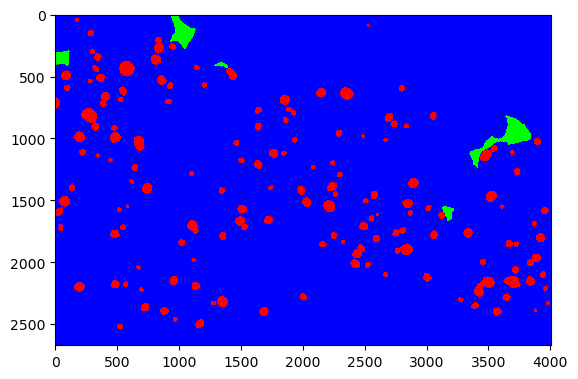

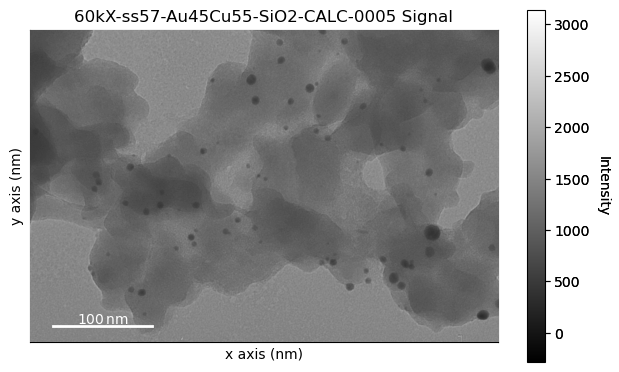

In [16]:
img = hs.load(AuCuSiO2_Path / f"{image_path}.dm3")
img.plot()

(-0.5, 4007.5, 2671.5, -0.5)

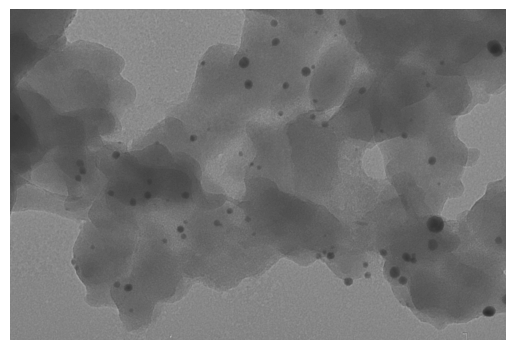

In [46]:
img = hs.load(AuCuSiO2_Path / f"{image_path}.dm3")
plt.imshow(img.data, cmap='gray')
plt.axis('off')

In [18]:
def plot_labeled_image(image_path):
    # Load the image
    label_array = np.array(Image.open(f"{image_path}+_lab.tif"))

    # Get unique values
    unique_values = np.unique(label_array)

    # Check if there are exactly 3 non-zero values (assuming 0 is unlabelled)
    if len(unique_values) != 3:
        raise ValueError("Unlabelled pixels or incorrect number of labels: expected exactly 3 unique values.")

    # Define colors for each value (assuming values are 1, 2, 3)
    colors = [
        [0, 1, 0, 1],    # Value 1 (green)
        [0, 0, 1, 1],    # Value 2 (blue)
        [1, 0, 0, 1]     # Value 3 (red)
    ]

    # Create a custom colormap
    cmap = ListedColormap(colors)

    # Plot the image
    plt.imshow(label_array, cmap=cmap, vmin=1, vmax=3)
    plt.axis('off')
    plt.show()

Value 1: 2814609 pixels
Value 2: 7702270 pixels
Value 3: 192497 pixels


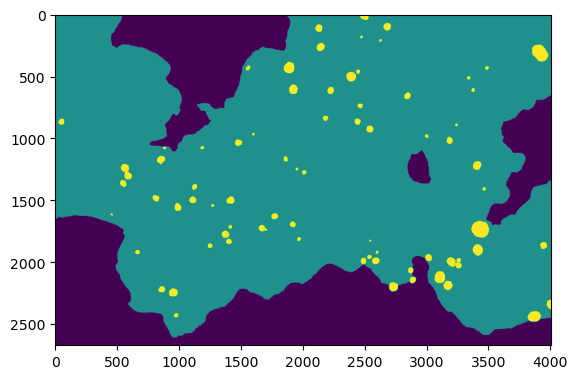

In [30]:
image = Image.open(AuCuSiO2_Path / labelling_Path)
plt.imshow(image)

image_array = np.array(image)

# Count pixels for each unique value
unique_values, counts = np.unique(image_array, return_counts=True)

# Print the results
for value, count in zip(unique_values, counts):
    print(f"Value {value}: {count} pixels")

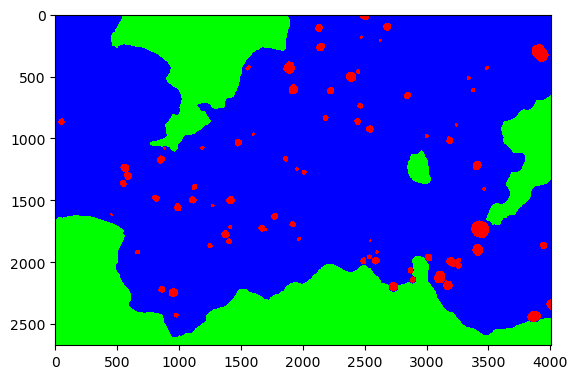

In [36]:
colors = [
    [0, 0, 0, 1],    # Background (value 0, black)
    [0, 1, 0, 1],    # Value 1 (green)
    [0, 0, 1, 1],    # Value 2 (blue)
    [1, 0, 0, 1]     # Value 3 (red)
]

# Create a custom colormap
cmap = ListedColormap(colors)

# Display the image with the custom colormap
plt.imshow(image_array, cmap=cmap, vmin=0, vmax=3)

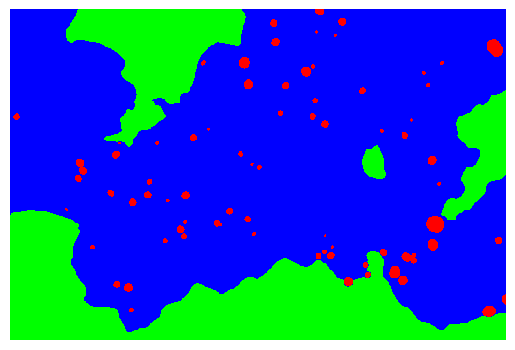

In [40]:
plot_labeled_image(AuCuSiO2_Path / labelling_Path)

In [55]:
def showLAB(LABarray):
    
    cmap = mcolors.ListedColormap(['white', 'white', 'red'])
    norm = mcolors.BoundaryNorm([0.5, 1.5, 2.5, 3.5], cmap.N)
    plt.imshow(LABarray, cmap=cmap, norm=norm)
    
    red_patch = mpatches.Patch(color='red', label='1')
    green_patch = mpatches.Patch(color='green', label='2')
    blue_patch = mpatches.Patch(color='blue', label='3')
    #plt.legend(handles=[red_patch, green_patch, blue_patch], loc='best')
    plt.show()

def binTEMimg(TEMpath, binScale = 2):
    HSimg = hs.load(path.join(TEMpath))
    binned = HSimg.rebin(scale=[binScale, binScale])
    print(binned.data.shape)
    plt.imshow(binned, cmap='gray')
    return binned.data

def binLABimg(LABarray, binScale = 2):
    binned = block_reduce(LABarray, block_size=(binScale, binScale), func=lambda block, axis=None: np.round(np.mean(block, axis=axis)).astype(int))
    print(binned.shape)
    plt.imshow(binned, cmap='gray')
    return binned

In [30]:
plt.close()
lab = hs.load(AuCuSiO2_Path / image_path).data
unique_values, count = np.unique(lab, return_counts=True)
print(('Unique_values = {}, count = {}').format(unique_values, count))
showLAB(lab)

Unique_values = [-284.44913  252.52032  257.7075  ... 3020.0413  3091.1296  3141.788  ], count = [1 1 1 ... 1 1 1]


NameError: name 'showLAB' is not defined

In [21]:
lab[lab == 1] = 0
lab[lab == 2] = 0
lab[lab == 3] = 255
plt.imshow(lab, cmap='gray')

In [22]:
labArray = binLABimg(lab)
labArray

(1336, 2004)


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [23]:
plt.close()
imgArray = binTEMimg(dm3Path)
imgArray.shape

(1336, 2004)


(1336, 2004)

In [46]:
modelName = r'AuCu%SiO2_binned'

directory, file_name = path.split(dm3Path)

imgPath = path.join(directory, modelName, file_name.split('.dm3')[0]+'_img')
labPath = path.join(directory, modelName, file_name.split('.dm3')[0]+'_lab')
makedirs(path.join(directory, modelName), exist_ok=True)

print(imgPath)
print(labPath)

imageio.imwrite('{}.tif'.format(imgPath), imgArray)
imageio.imwrite('{}.tif'.format(labPath), labArray)

D:\Owncloud\Shared\LRS-FCMAT_DL_data\Images\SS57-SiO2-Cal\AuCu%SiO2_binned\60kX-ss57-Au45Cu55-SiO2-CALC-0005_img
D:\Owncloud\Shared\LRS-FCMAT_DL_data\Images\SS57-SiO2-Cal\AuCu%SiO2_binned\60kX-ss57-Au45Cu55-SiO2-CALC-0005_lab


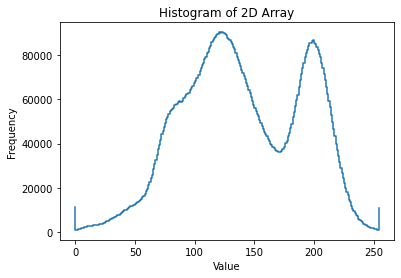

In [68]:
fdoPath = r'C:\DataCNRS_DesktopPerso\AI\2024-02_Maxime\2024-06_SemanticSegmentation\Training\AuCu-SiO2\Train\Image\60kX-ss57-Au45Cu55-SiO2-CALC-0005.fda'

image = read_fda(fdoPath)

image.shape

array_1d = image.flatten()

# Step 3: Plot the histogram
hist, bin_edges = np.histogram(array_1d, bins=np.arange(array_1d.min(), array_1d.max() + 2) - 0.5)

plt.plot(bin_edges[:-1], hist, drawstyle='steps-mid')
plt.title('Histogram of 2D Array')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

(1336, 2004)


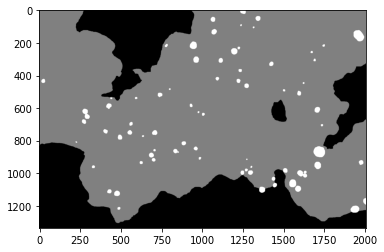

In [23]:
binLABimg(labPath)

In [7]:
checkPixels(labPath)

NameError: name 'checkPixels' is not defined

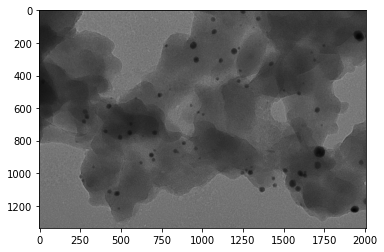

In [38]:
HSimg = hs.load(path.join(dm3Path))
binned = HSimg.rebin(scale=[2, 2])
plt.imshow(binned, cmap='gray')

Unique_values = [1 2 3], count = [2814609 7702270  192497]
Unique_values = [0 1], count = [10516879   192497]


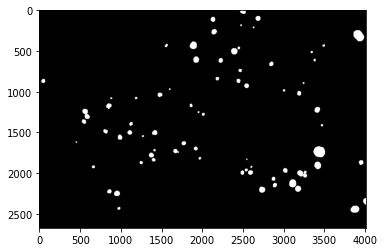

In [5]:
HSimg = hs.load(path.join(labPath))
unique_values, count = np.unique(HSimg, return_counts=True)
print(('Unique_values = {}, count = {}').format(unique_values, count))
mod_image = HSimg.data
mod_image[mod_image == 1] = 0
mod_image[mod_image == 2] = 0
mod_image[mod_image == 3] = 1

plt.imshow(mod_image, cmap='gray')
unique_values, count = np.unique(mod_image, return_counts=True)
print(('Unique_values = {}, count = {}').format(unique_values, count))

(1336, 2004)
Unique_values = [0 1], count = [2630167   47177]


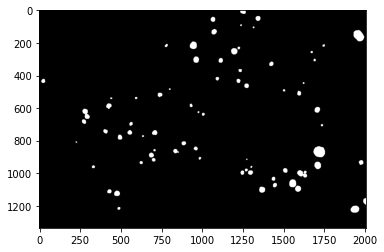

In [ ]:
s = hs.load(dm3Path).data

array_1d = s.flatten()

# Step 3: Plot the histogram
hist, bin_edges = np.histogram(array_1d, bins=np.arange(array_1d.min(), array_1d.max() + 2) - 0.5)

plt.plot(bin_edges[:-1], hist, drawstyle='steps-mid')
plt.title('Histogram of 2D Array')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

Unique_values = [1 2 3], count = [2814609 7702270  192497]
Unique_values = [ 4  5  6  7  8  9 10 11 12], count = [ 701570    1109    1826    1178 1921590    1126    1801     979   46165]


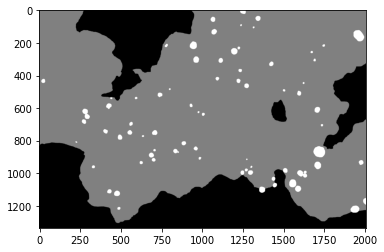

In [37]:
HSimg = hs.load(path.join(labPath))
unique_values, count = np.unique(HSimg, return_counts=True)
print(('Unique_values = {}, count = {}').format(unique_values, count))
binned = HSimg.rebin(scale=[2, 2])
unique_values, count = np.unique(binned, return_counts=True)
print(('Unique_values = {}, count = {}').format(unique_values, count))
plt.imshow(binned, cmap='gray')

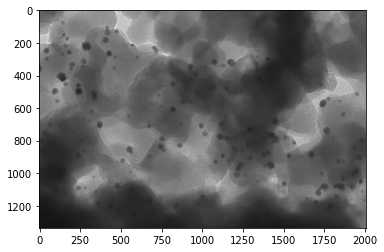

In [23]:
plt.imshow(binned, cmap='gray')

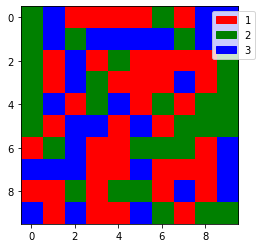

'C:\\DataCNRS\\DropSU\\Shared\\NP%Si_labelling\\Images\\SS57-SiO2-Cal\\60kX-ss57-Au45Cu55-SiO2-CALC-0008.dm3'

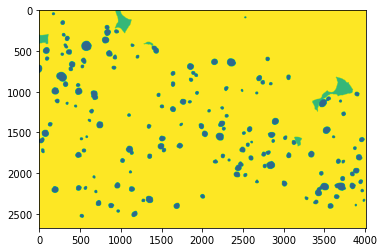

Unique_values = [0 1 2 3], count = [       7   467837    99456 10142076]


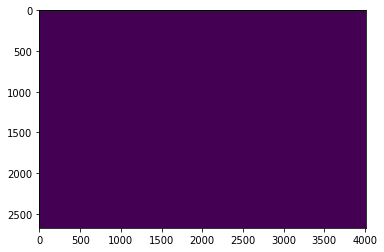

Unique_values = [1 2 3], count = [  467844    99456 10142076]
